# Baseline Evaluation: Metrics and Curves
Owner: Anupama Singh

Reads the out-of-fold predictions saved by the four model notebooks and computes every metric and curve in one place. Run the four model notebooks first.

| Metric | Used for | Meaning |
|---|---|---|
| **ROC AUC** | all models | Chance a random high-growth student is ranked above a random low-growth one. 0.5 = guessing |
| **PR-AUC** | all models | Area under the precision-recall curve (average precision). The team's main metric. Guessing = share of label 1 |
| **Accuracy** | all models | Share of students labeled correctly |
| **Precision** | all models | Of the students predicted as high growth, the share that really were |
| **Recall** | all models | Of the students who really were high growth, the share the model found |
| **MAE** | regressors | Mean absolute error of the predicted gain, in points |
| **MSE** | regressors | Mean squared error of the predicted gain, in points²; large misses count much more |
| **RMSE** | regressors | Square root of MSE, back in points |

All metrics are computed per fold and averaged over the 5 folds, the same way as Megha's notebooks.

## 1. Load the predictions

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
                             accuracy_score, precision_score, recall_score,
                             mean_absolute_error, mean_squared_error)

# Local results/ folder when run in the repo; otherwise read the files from GitHub
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)
GITHUB = "https://raw.githubusercontent.com/meghagangal362015/cmpe257-early-reading-prediction/{branch}/results"


def read_result(name):
    if (RESULTS / name).exists():
        return pd.read_csv(RESULTS / name)
    for branch in ["main", "anupama"]:
        try:
            return pd.read_csv(f"{GITHUB.format(branch=branch)}/{name}")
        except Exception:
            continue
    raise FileNotFoundError(f"{name} not found locally or on GitHub. Run the model notebooks first.")


MODELS = {"Logistic Regression": "logistic_regression", "Decision Tree": "decision_tree",
          "Linear Regression": "linear_regression", "Decision Tree Regressor": "decision_tree_regressor"}
REGRESSORS = {"Linear Regression", "Decision Tree Regressor"}
TARGETS = {"RMwidRS": "Word Identification", "RMwdaRS": "Word Attack"}

predictions = pd.concat([read_result(f"{slug}_cv_predictions.csv") for slug in MODELS.values()],
                        ignore_index=True)
predictions["target"] = predictions["target"].map(TARGETS)
print(predictions.groupby(["model", "split"]).size().unstack())

split                    school  student
model                                   
Decision Tree              1412     1412
Decision Tree Regressor    1412     1412
Linear Regression          1412     1412
Logistic Regression        1412     1412


## 2. Metrics per fold

In [2]:
rows = []
for (model, split, target, fold), g in predictions.groupby(["model", "split", "target", "fold"], sort=False):
    y, s, p = g["true_label"], g["score"], g["pred_label"]
    row = {"model": model, "split": split, "target": target, "fold": fold,
           "ROC AUC": roc_auc_score(y, s),
           "PR-AUC": average_precision_score(y, s),
           "Accuracy": accuracy_score(y, p),
           "Precision": precision_score(y, p, zero_division=0),
           "Recall": recall_score(y, p, zero_division=0)}
    if model in REGRESSORS:           # error metrics on the predicted gain, in points
        row["MAE"] = mean_absolute_error(g["true_gain"], s)
        row["MSE"] = mean_squared_error(g["true_gain"], s)
        row["RMSE"] = row["MSE"] ** 0.5
    rows.append(row)
fold_metrics_table = pd.DataFrame(rows)
CLASSIFICATION = ["ROC AUC", "PR-AUC", "Accuracy", "Precision", "Recall"]
ERRORS = ["MAE", "MSE", "RMSE"]


def summary_table(split, metrics, models=None):
    part = fold_metrics_table[fold_metrics_table["split"] == split]
    if models:
        part = part[part["model"].isin(models)]
    agg = part.groupby(["target", "model"], sort=False)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        out[m] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(agg[(m, "mean")], agg[(m, "std")])]
    return out

## 3. Classification metrics: ROC AUC, PR-AUC, accuracy, precision, recall
Mean ± standard deviation over the 5 folds. Precision and recall are for label 1 (high growth).

### School split (main: test schools never seen in training)

In [3]:
summary_table("school", CLASSIFICATION)

,,ROC AUC,PR-AUC,Accuracy,Precision,Recall
target,model,,,,,
Word Identification,Logistic Regression,0.671 ± 0.057,0.684 ± 0.047,0.640 ± 0.052,0.656 ± 0.060,0.728 ± 0.122
Word Attack,Logistic Regression,0.614 ± 0.039,0.694 ± 0.078,0.611 ± 0.063,0.635 ± 0.065,0.784 ± 0.095
Word Identification,Decision Tree,0.653 ± 0.066,0.649 ± 0.044,0.636 ± 0.053,0.639 ± 0.057,0.779 ± 0.056
Word Attack,Decision Tree,0.556 ± 0.054,0.624 ± 0.067,0.558 ± 0.034,0.618 ± 0.055,0.686 ± 0.126
Word Identification,Linear Regression,0.672 ± 0.064,0.687 ± 0.049,0.644 ± 0.052,0.659 ± 0.054,0.719 ± 0.079
Word Attack,Linear Regression,0.622 ± 0.025,0.703 ± 0.056,0.604 ± 0.044,0.641 ± 0.049,0.723 ± 0.104
Word Identification,Decision Tree Regressor,0.647 ± 0.036,0.641 ± 0.052,0.646 ± 0.030,0.639 ± 0.021,0.795 ± 0.104
Word Attack,Decision Tree Regressor,0.554 ± 0.036,0.619 ± 0.063,0.585 ± 0.034,0.619 ± 0.059,0.772 ± 0.089


### Student split (schools can appear in training and test)

In [4]:
summary_table("student", CLASSIFICATION)

,,ROC AUC,PR-AUC,Accuracy,Precision,Recall
target,model,,,,,
Word Identification,Logistic Regression,0.667 ± 0.069,0.688 ± 0.090,0.637 ± 0.068,0.656 ± 0.117,0.732 ± 0.061
Word Attack,Logistic Regression,0.634 ± 0.031,0.707 ± 0.042,0.616 ± 0.046,0.643 ± 0.058,0.790 ± 0.020
Word Identification,Decision Tree,0.636 ± 0.087,0.648 ± 0.117,0.612 ± 0.071,0.628 ± 0.102,0.708 ± 0.064
Word Attack,Decision Tree,0.597 ± 0.052,0.664 ± 0.067,0.601 ± 0.068,0.636 ± 0.083,0.774 ± 0.041
Word Identification,Linear Regression,0.674 ± 0.072,0.695 ± 0.091,0.649 ± 0.071,0.661 ± 0.112,0.733 ± 0.042
Word Attack,Linear Regression,0.632 ± 0.034,0.711 ± 0.033,0.602 ± 0.041,0.647 ± 0.053,0.721 ± 0.026
Word Identification,Decision Tree Regressor,0.646 ± 0.034,0.631 ± 0.066,0.662 ± 0.047,0.634 ± 0.057,0.864 ± 0.106
Word Attack,Decision Tree Regressor,0.594 ± 0.037,0.651 ± 0.032,0.609 ± 0.026,0.638 ± 0.031,0.778 ± 0.079


## 4. Error metrics for the regression models: MAE, MSE, RMSE
Errors of the predicted gain, in points (MSE in points²). The reference row is always predicting the training folds' average gain.

In [5]:
# Reference: predict the training folds' average gain for every test student
reference = []
for (split, target, fold), g in predictions[predictions["model"] == "Linear Regression"].groupby(
        ["split", "target", "fold"]):
    train_mean = predictions[(predictions["model"] == "Linear Regression") & (predictions["split"] == split)
                             & (predictions["target"] == target) & (predictions["fold"] != fold)]["true_gain"].mean()
    mse = mean_squared_error(g["true_gain"], np.full(len(g), train_mean))
    reference.append({"split": split, "target": target, "fold": fold,
                      "MAE": mean_absolute_error(g["true_gain"], np.full(len(g), train_mean)),
                      "MSE": mse, "RMSE": mse ** 0.5})
reference = pd.DataFrame(reference)

errors = []
for split in ["school", "student"]:
    table = summary_table(split, ERRORS, REGRESSORS).reset_index()
    ref = reference[reference["split"] == split].groupby("target")[ERRORS].agg(["mean", "std"])
    for target in ref.index:
        row = {"target": target, "model": "Reference: average gain"}
        row.update({m: f"{ref.loc[target, (m, 'mean')]:.3f} ± {ref.loc[target, (m, 'std')]:.3f}" for m in ERRORS})
        table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    errors.append(table.assign(split=split))
errors = pd.concat(errors).set_index(["split", "target", "model"]).sort_index()
errors

MAE  \
split   target              model                                    
school  Word Attack         Decision Tree Regressor  5.986 ± 0.158   
                            Linear Regression        5.699 ± 0.278   
                            Reference: average gain  5.937 ± 0.268   
        Word Identification Decision Tree Regressor  6.701 ± 0.431   
                            Linear Regression        6.513 ± 0.483   
                            Reference: average gain  7.133 ± 0.478   
student Word Attack         Decision Tree Regressor  5.865 ± 0.659   
                            Linear Regression        5.717 ± 0.553   
                            Reference: average gain  5.941 ± 0.559   
        Word Identification Decision Tree Regressor  6.718 ± 0.153   
                            Linear Regression        6.605 ± 0.235   
                            Reference: average gain  7.160 ± 0.416   

                                                                 MSE  \
split   target              model                                      
school  Word Attack         Decision Tree Regressor   54.927 ± 4.025   
                            Linear Regression         49.555 ± 4.828   
                            Reference: average gain   54.618 ± 4.851   
        Word Identification Decision Tree Regressor  71.840 ± 10.356   
                            Linear Regression         67.872 ± 9.984   
                            Reference: average gain  78.449 ± 11.075   
student Word Attack         Decision Tree Regressor  53.862 ± 10.828   
                            Linear Regression         49.839 ± 8.673   
                            Reference: average gain  54.793 ± 10.435   
        Word Identification Decision Tree Regressor   71.708 ± 5.680   
                            Linear Regression         68.644 ± 5.363   
                            Reference: average gain   78.944 ± 9.973   

                                                              RMSE  
split   target              model                                   
school  Word Attack         Decision Tree Regressor  7.407 ± 0.276  
                            Linear Regression        7.033 ± 0.351  
                            Reference: average gain  7.385 ± 0.330  
        Word Identification Decision Tree Regressor  8.459 ± 0.597  
                            Linear Regression        8.221 ± 0.606  
                            Reference: average gain  8.840 ± 0.610  
student Word Attack         Decision Tree Regressor  7.310 ± 0.728  
                            Linear Regression        7.039 ± 0.604  
                            Reference: average gain  7.376 ± 0.696  
        Word Identification Decision Tree Regressor  8.463 ± 0.338  
                            Linear Regression        8.280 ± 0.325  
                            Reference: average gain  8.871 ± 0.550

## 5. ROC curves (school split)
True positive rate (recall) against false positive rate as the decision threshold moves. The closer to the top-left corner, the better; the dashed diagonal is guessing. Each curve pools the out-of-fold predictions of all 706 students, so its AUC can differ slightly from the fold average in the tables.

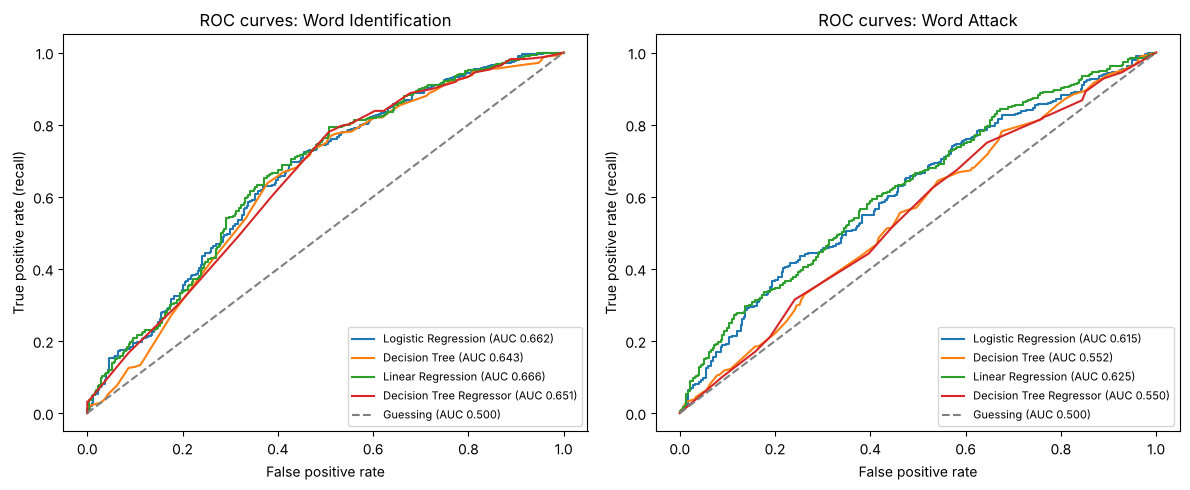

In [6]:
school = predictions[predictions["split"] == "school"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target in zip(axes, TARGETS.values()):
    for model, g in school[school["target"] == target].groupby("model", sort=False):
        fpr, tpr, _ = roc_curve(g["true_label"], g["score"])
        ax.plot(fpr, tpr, label=f"{model} (AUC {roc_auc_score(g['true_label'], g['score']):.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Guessing (AUC 0.500)")
    ax.set_title(f"ROC curves: {target}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate (recall)")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS / "baseline_roc_curves.png", dpi=150)
plt.show()

## 6. Precision-recall curves (school split)
Precision against recall as the decision threshold moves. The dashed line is guessing: precision equals the share of label 1. PR-AUC (average precision) summarizes each curve.

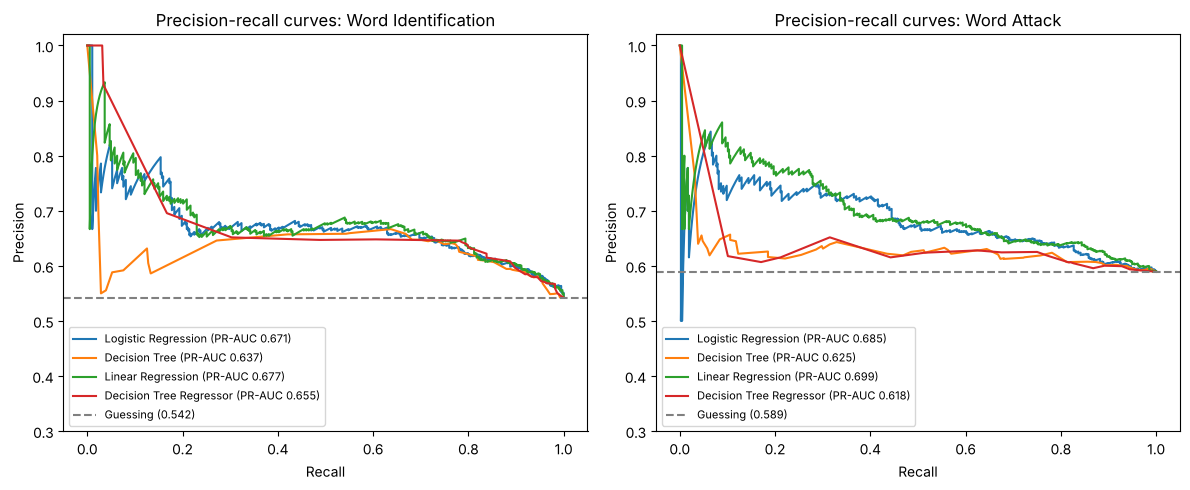

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target in zip(axes, TARGETS.values()):
    part = school[school["target"] == target]
    for model, g in part.groupby("model", sort=False):
        precision, recall, _ = precision_recall_curve(g["true_label"], g["score"])
        ax.plot(recall, precision,
                label=f"{model} (PR-AUC {average_precision_score(g['true_label'], g['score']):.3f})")
    base_rate = part.drop_duplicates("StuID")["true_label"].mean()
    ax.axhline(base_rate, linestyle="--", color="gray", label=f"Guessing ({base_rate:.3f})")
    ax.set_title(f"Precision-recall curves: {target}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_ylim(0.3, 1.02)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(RESULTS / "baseline_precision_recall_curves.png", dpi=150)
plt.show()

## 7. Comparison with the paper and the team (school split)
- **Paper:** Logistic Regression from Table 1 of Shangguan et al. (2024), which reports ROC AUC and accuracy.
- **Team:** Megha's Random Forest, XGBoost and Naive Bayes, read from her result files. They use the same 706 students, 16 features and identical school folds, so the numbers compare directly.

In [8]:
ours = (fold_metrics_table[fold_metrics_table["split"] == "school"]
        .groupby(["target", "model"], sort=False)[["ROC AUC", "PR-AUC", "Accuracy"]].mean()
        .reset_index().assign(source="Anupama (baselines)"))

paper = pd.DataFrame([("Word Identification", "Logistic Regression", 0.6121, np.nan, 0.6119),
                      ("Word Attack", "Logistic Regression", 0.5591, np.nan, 0.5923)],
                     columns=["target", "model", "ROC AUC", "PR-AUC", "Accuracy"]).assign(source="Paper (Table 1)")

team = []
try:
    rf_xgb = read_result("random_forest_vs_xgboost_mean_results.csv").rename(
        columns={"Target": "target", "Model": "model"})
    nb_ = read_result("naive_bayes_summary.csv").rename(
        columns={"Target": "target", "Mean_Accuracy": "Accuracy", "Mean_PR_AUC": "PR-AUC"}).assign(model="Naive Bayes")
    team = pd.concat([rf_xgb, nb_[["target", "model", "Accuracy", "PR-AUC"]]]).assign(source="Megha")
except FileNotFoundError as error:
    print("Team results not found:", error)

comparison = pd.concat([ours, paper] + ([team] if len(team) else []), ignore_index=True)
comparison = comparison[["target", "source", "model", "ROC AUC", "PR-AUC", "Accuracy"]].round(3)
comparison.sort_values(["target", "PR-AUC"], ascending=[False, False], na_position="last").reset_index(drop=True)

,target,source,model,ROC AUC,PR-AUC,Accuracy
0,Word Identification,Megha,Random Forest,NaN,0.692,0.638
1,Word Identification,Anupama (baselines),Linear Regression,0.672,0.687,0.644
2,Word Identification,Anupama (baselines),Logistic Regression,0.671,0.684,0.640
3,Word Identification,Megha,XGBoost,NaN,0.684,0.618
4,Word Identification,Anupama (baselines),Decision Tree,0.653,0.649,0.636
5,Word Identification,Megha,Naive Bayes,NaN,0.643,0.627
6,Word Identification,Anupama (baselines),Decision Tree Regressor,0.647,0.641,0.646
7,Word Identification,Paper (Table 1),Logistic Regression,0.612,NaN,0.612
8,Word Attack,Anupama (baselines),Linear Regression,0.622,0.703,0.604
9,Word Attack,Anupama (baselines),Logistic Regression,0.614,0.694,0.611


## 8. Save the results

In [9]:
fold_metrics_table.to_csv(RESULTS / "baseline_models_cv_fold_metrics.csv", index=False)
summary = (fold_metrics_table.groupby(["split", "target", "model"], sort=False)[CLASSIFICATION + ERRORS]
           .agg(["mean", "std"]).round(4))
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary.reset_index().to_csv(RESULTS / "baseline_models_cv_summary.csv", index=False)
comparison.to_csv(RESULTS / "baseline_vs_paper_and_team.csv", index=False)
print("Saved baseline_models_cv_fold_metrics.csv, baseline_models_cv_summary.csv, "
      f"baseline_vs_paper_and_team.csv to {RESULTS}/")

Saved baseline_models_cv_fold_metrics.csv, baseline_models_cv_summary.csv, baseline_vs_paper_and_team.csv to ../results/
